# Product Analytics Platform

Ноутбук показывает, что видно в данных продукта и какие выводы из этого следуют. Он отвечает на простые вопросы бизнеса: как растёт аудитория, насколько хорошо продукт удерживает пользователей, как работает воронка активации и откуда берётся выручка.

Данные синтетические, их готовит генератор из src/generator. Дальше они проходят через ELT в DuckDB и слой метрик, а ноутбук читает уже готовые витрины и таблицы metric_ из data/warehouse.duckdb.

Перед запуском соберите данные командой make pipeline.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
PAL = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2"]

con = duckdb.connect("../data/warehouse.duckdb", read_only=True)
ANALYSIS_END = "2025-08-31"
print("Таблиц в warehouse:", len(con.execute("SHOW TABLES").fetchall()))


Таблиц в warehouse: 16


## Ключевые показатели

Короткая сводка главных цифр на конец окна анализа.

In [2]:
s = con.execute("SELECT * FROM metric_summary").df().iloc[0]
summary = pd.DataFrame({
    "Метрика": ["Всего пользователей", "Платящих сейчас", "Free to Paid",
                "Отток платящих", "North Star (WAU)", "Текущий MRR", "Выручка всего"],
    "Значение": [f"{int(s.total_users):,}", f"{int(s.paying_users):,}",
                 f"{s.free_to_paid_rate:.1%}", f"{s.paid_churn_rate:.1%}",
                 f"{int(s.north_star_wau):,}", f"{s.current_mrr:,.0f} ₽",
                 f"{s.total_revenue:,.0f} ₽"],
})
summary


,Метрика,Значение
0,Всего пользователей,"9,306"
1,Платящих сейчас,704
2,Free to Paid,10.4%
3,Отток платящих,27.2%
4,North Star (WAU),"1,816"
5,Текущий MRR,"34,876 ₽"
6,Выручка всего,"240,046 ₽"


## Рост аудитории

Аудитория стабильно растёт весь год. В дневной активности хорошо видна недельная сезонность, будни выше выходных, а всплески привлечения совпадают с маркетинговыми кампаниями вроде чёрной пятницы.

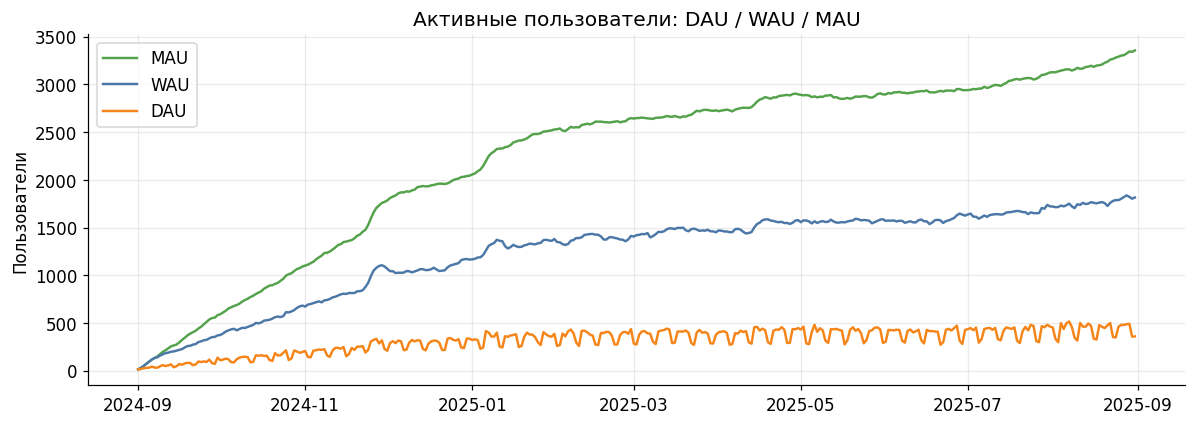

WAU за год вырос с 134 до 1816


In [3]:
au = con.execute(f'''
    SELECT activity_date, dau, wau, mau
    FROM metric_active_users WHERE activity_date <= DATE '{ANALYSIS_END}' ORDER BY 1''').df()
fig, ax = plt.subplots(figsize=(11, 4))
for col, c in zip(["mau", "wau", "dau"], [PAL[2], PAL[0], PAL[1]]):
    ax.plot(au.activity_date, au[col], label=col.upper(), color=c, lw=1.6)
ax.set_title("Активные пользователи: DAU / WAU / MAU")
ax.legend(loc="upper left"); ax.set_ylabel("Пользователи")
plt.tight_layout(); plt.show()
print("WAU за год вырос с", int(au.wau.iloc[6]), "до", int(au.wau.iloc[-1]))


## Удержание по когортам

Картина обычная для продукта. После первой недели удержание резко падает, а дальше выходит на плато у лояльного ядра. Ниже кривая day-N retention по всей базе.

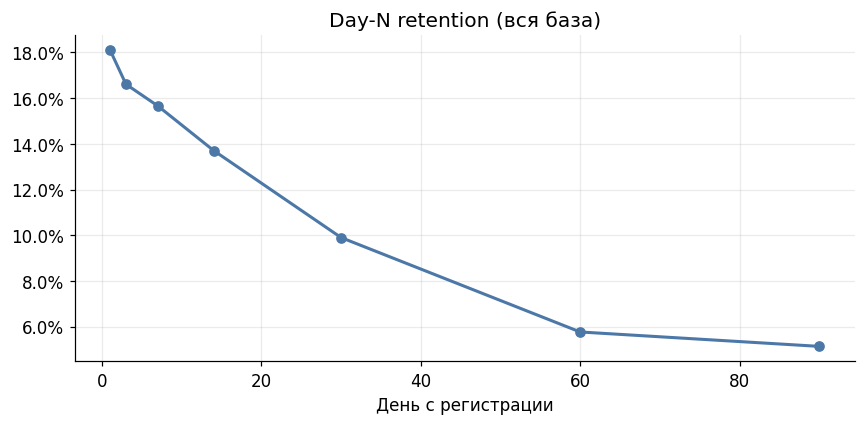

,day_number,retention
0,1,18.1%
1,3,16.6%
2,7,15.7%
3,14,13.7%
4,30,9.9%
5,60,5.8%
6,90,5.1%


In [4]:
r = con.execute("SELECT day_number, retention_rate FROM metric_retention_dayn ORDER BY 1").df()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(r.day_number, r.retention_rate, "o-", color=PAL[0], lw=2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Day-N retention (вся база)"); ax.set_xlabel("День с регистрации")
plt.tight_layout(); plt.show()
r.assign(retention=r.retention_rate.map("{:.1%}".format))[["day_number", "retention"]]


## Воронка активации

Воронка строго вложенная, шаги идут по порядку: signup, login, create_project, run_report, purchase. Главный обрыв это переход к оплате. До продукта доходят почти все, а платит лишь небольшая доля. Здесь и лежит основной потенциал роста выручки.

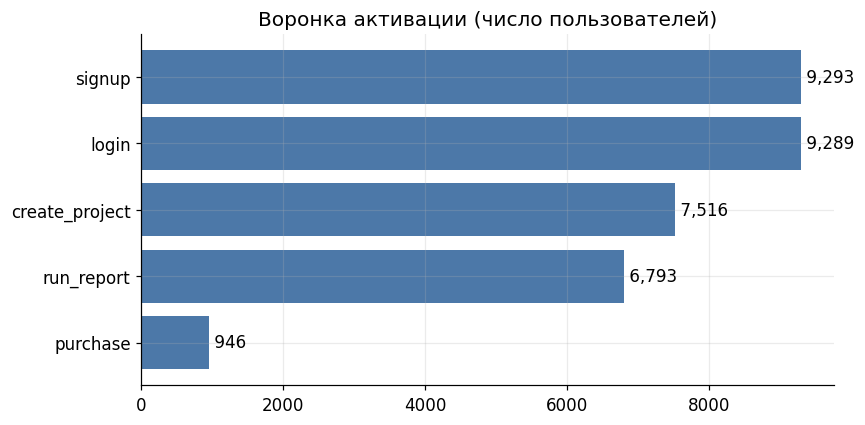

,step,users,conv_from_prev
0,signup,9293,100.0%
1,login,9289,100.0%
2,create_project,7516,80.9%
3,run_report,6793,90.4%
4,purchase,946,13.9%


In [5]:
f = con.execute("SELECT step, users, conv_from_prev FROM metric_activation_funnel ORDER BY step_order").df()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(f.step[::-1], f.users[::-1], color=PAL[0])
for i, (u, s) in enumerate(zip(f.users[::-1], f.step[::-1])):
    ax.text(u, i, f" {u:,}", va="center")
ax.set_title("Воронка активации (число пользователей)")
plt.tight_layout(); plt.show()
f.assign(conv_from_prev=f.conv_from_prev.map("{:.1%}".format))


## Выручка и сегменты

MRR растёт за счёт притока платящих. Разбивка по планам показывает вклад pro и enterprise, а разбивка по каналам показывает, какие источники приносят деньги, а не только регистрации.

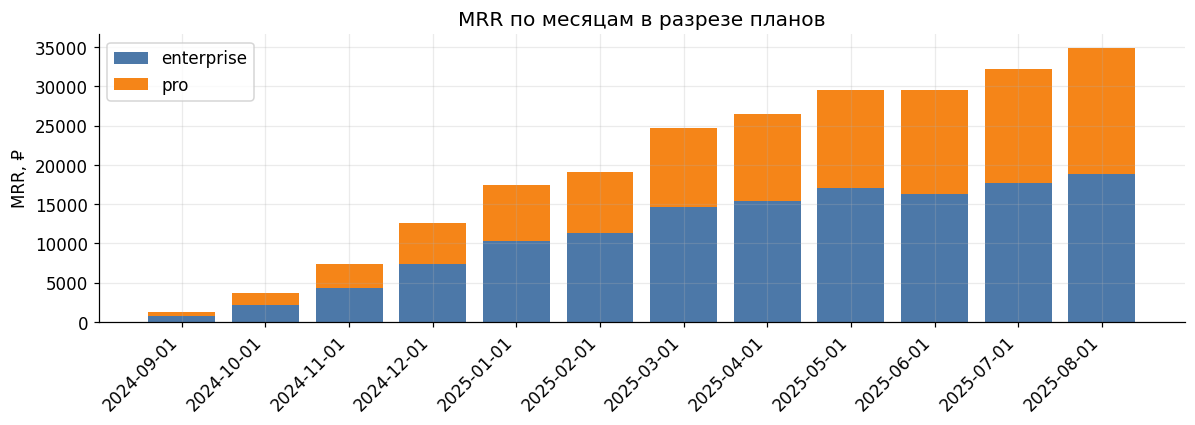

In [6]:
mrr = con.execute(f'''
    SELECT event_month, plan, mrr FROM metric_mrr
    WHERE event_month <= date_trunc('month', DATE '{ANALYSIS_END}') ORDER BY 1''').df()
piv = mrr.pivot(index="event_month", columns="plan", values="mrr").fillna(0)
fig, ax = plt.subplots(figsize=(11, 4))
bottom = None
for i, plan in enumerate(piv.columns):
    ax.bar(piv.index.astype(str), piv[plan], bottom=bottom, label=plan, color=PAL[i % len(PAL)], width=.8)
    bottom = piv[plan] if bottom is None else bottom + piv[plan]
ax.set_title("MRR по месяцам в разрезе планов"); ax.legend()
plt.xticks(rotation=45, ha="right"); ax.set_ylabel("MRR, ₽")
plt.tight_layout(); plt.show()


In [7]:
seg = con.execute('''
    SELECT segment_value AS channel, users, paying_users, conversion_rate, revenue
    FROM metric_segments WHERE segment_type='channel' ORDER BY revenue DESC''').df()
seg.assign(conversion_rate=seg.conversion_rate.map("{:.1%}".format),
           revenue=seg.revenue.map("{:,.0f} ₽".format))


,channel,users,paying_users,conversion_rate,revenue
0,organic,4143,311.0,10.4%,"103,591 ₽"
1,paid,3265,260.0,10.2%,"79,368 ₽"
2,referral,1898,133.0,10.6%,"57,087 ₽"


## Выводы

Рост здоровый. WAU и MAU растут весь год, видна недельная сезонность и отклик на маркетинговые кампании, значит каналы привлечения работают.

Главная точка роста это удержание. Больше всего пользователей отваливается на первой неделе, поэтому вложения в онбординг и в активацию первого дня дадут самый быстрый эффект.

Монетизация упирается в шаг оплаты. Продуктовые шаги воронки проходят почти все, а конверсия в оплату низкая. Это место для экспериментов с ценой и с триггерами апгрейда.

Сегменты сильно отличаются. Power-пользователи удерживаются и платят заметно лучше, их выгодно растить отдельно.

Отток платящих пока под контролем, но за ним стоит следить, чтобы рост MRR не маскировал ускорение оттока в отдельных когортах.

Что можно сделать дальше: прогноз MRR, расчёт LTV и CAC по каналам, A/B-тесты онбординга.